# Preliminary Image Processing with OpenCV

This notebook processes images according to their folder and filename:

- `ED/Edge.jpg`: Canny edge detection.
- `PP/gamma.jpg`: gamma point processing for an overexposed image.
- `SF/sharpen.jpg`: sharpening with an unsharp mask.
- `SF/SpatialFilteringDenoising1.jpg` and `2.jpg`: spatial denoising.
- The three processed `SF` results are copied into `HP`, then every image in `HP` receives luminance-histogram processing with CLAHE.

The notebook works locally and in Google Colab. In Colab, either upload the complete `Preli` folder to `/content/Preli`, or place it in Google Drive and adjust `COLAB_PRELI_DIR` in the setup cell. All result files are reproducibly overwritten on rerun.

## 1. Setup

In [1]:
import sys
import subprocess
import importlib.util
from pathlib import Path

# Install only missing packages. The headless OpenCV build avoids desktop-GUI dependencies.
required_packages = {
    "cv2": "opencv-python-headless",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
}
missing_packages = [package for module, package in required_packages.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    print(f"Installing missing packages: {', '.join(missing_packages)}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

import cv2

import numpy as np
import matplotlib
from IPython import get_ipython

# Force an inline backend in notebooks and a non-interactive backend in plain Python.
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
else:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
MOUNT_GOOGLE_DRIVE = True  # Used only in Colab; set False when using /content/Preli.
COLAB_PRELI_DIR = Path("/content/drive/MyDrive/DIP/Project/Preli")

plt.rcParams.update({
    "figure.figsize": (14, 6),
    "axes.titlesize": 12,
    "axes.grid": False,
})

print(f"Environment: {'Google Colab' if IN_COLAB else 'Local Jupyter'}")
print(f"OpenCV version: {cv2.__version__}")

Environment: Local Jupyter
OpenCV version: 5.0.0


In [2]:
# Resolve Preli without hard-coding the local Windows path.
if IN_COLAB and MOUNT_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
    except Exception as exc:
        print(f"Google Drive was not mounted: {exc}")

def looks_like_preli(path: Path) -> bool:
    return path.is_dir() and all((path / name).is_dir() for name in ("ED", "PP", "SF", "HP"))

cwd = Path.cwd().resolve()
candidates = [
    Path("/content/Preli"),
    Path("/content/preli"),
    COLAB_PRELI_DIR,
    cwd,
    cwd / "Preli",
    cwd / "preli",
    cwd / "Project" / "Preli",
    cwd / "project" / "preli",
]
for parent in cwd.parents:
    candidates.extend([parent / "Project" / "Preli", parent / "project" / "preli"])

BASE_DIR = next((path.resolve() for path in candidates if looks_like_preli(path)), None)
if BASE_DIR is None:
    raise FileNotFoundError(
        "Could not locate Preli. In Colab, upload it to /content/Preli or set "
        "COLAB_PRELI_DIR. Locally, run this notebook from Preli or a parent DIP folder."
    )

ED_DIR = BASE_DIR / "ED"
PP_DIR = BASE_DIR / "PP"
SF_DIR = BASE_DIR / "SF"
HP_DIR = BASE_DIR / "HP"
OUTPUT_DIR = BASE_DIR / "outputs"
for subfolder in ("ED", "PP", "SF", "HP"):
    (OUTPUT_DIR / subfolder).mkdir(parents=True, exist_ok=True)

print(f"Using Preli folder: {BASE_DIR}")
print(f"Outputs will be saved under: {OUTPUT_DIR}")

Using Preli folder: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli
Outputs will be saved under: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs


## 2. Shared helpers and parameters

In [3]:
PARAMS = {
    "canny_low": 50,
    "canny_high": 150,
    "gamma_trials": (1.4, 1.8, 2.2, 2.6),
    "selected_gamma": 2.2,  # Selected by visual inspection after the trial grid.
    "unsharp_amount": 1.0,
    "median_kernel_trials": (3, 5, 7, 9),
    "selected_median_kernel": 9,  # Selected for stronger noise removal before CLAHE.
    "bilateral_d": 7,
    "bilateral_sigma_color": 35,
    "bilateral_sigma_space": 35,
    "clahe_clip_limit": 2.0,
    "clahe_grid": (8, 8),
}
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def read_bgr(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"OpenCV could not read image: {path}")
    return image

def save_bgr(path: Path, image: np.ndarray) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"OpenCV could not write image: {path}")
    return path

def to_rgb(image_bgr: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

def gamma_correction(image_bgr: np.ndarray, gamma: float) -> np.ndarray:
    levels = np.linspace(0.0, 1.0, 256)
    lookup_table = np.clip((levels ** gamma) * 255.0, 0, 255).astype(np.uint8)
    return cv2.LUT(image_bgr, lookup_table)

def gamma_metrics(image_bgr: np.ndarray) -> dict:
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    return {
        "mean_brightness": float(np.mean(gray)),
        "clipped_highlights_pct": float(np.mean(gray >= 250) * 100.0),
    }

def spatial_denoise(image_bgr: np.ndarray, median_kernel: int) -> tuple[np.ndarray, np.ndarray]:
    median_result = cv2.medianBlur(image_bgr, median_kernel)
    final_result = cv2.bilateralFilter(
        median_result,
        d=PARAMS["bilateral_d"],
        sigmaColor=PARAMS["bilateral_sigma_color"],
        sigmaSpace=PARAMS["bilateral_sigma_space"],
    )
    return median_result, final_result

def show_images(images, titles, cmap=None, figsize=(16, 6)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for axis, image, title in zip(axes, images, titles):
        axis.imshow(image, cmap=cmap if image.ndim == 2 else None)
        axis.set_title(title)
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## 3. Edge detection — `ED/Edge.jpg`

Saved: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\ED\Edge_canny.png
Saved: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\ED\Edge_overlay.jpg


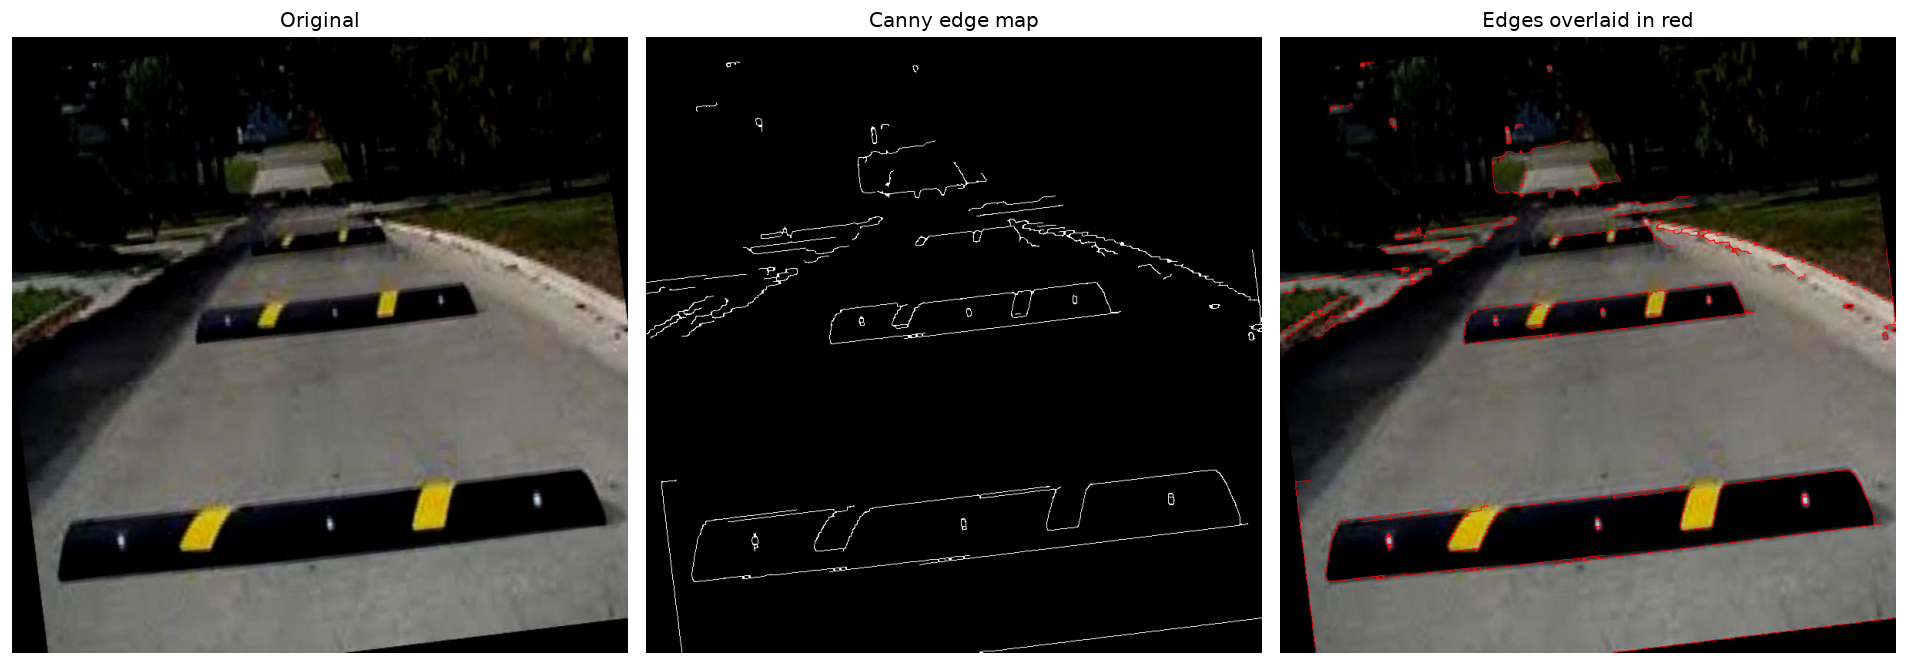

In [4]:
edge_path = ED_DIR / "Edge.jpg"
edge_source = read_bgr(edge_path)
edge_gray = cv2.cvtColor(edge_source, cv2.COLOR_BGR2GRAY)
edge_blurred = cv2.GaussianBlur(edge_gray, (5, 5), 1.2)
edge_map = cv2.Canny(edge_blurred, PARAMS["canny_low"], PARAMS["canny_high"])
edge_map = cv2.morphologyEx(edge_map, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
edge_overlay = edge_source.copy()
edge_overlay[edge_map > 0] = (0, 0, 255)

edge_map_path = save_bgr(OUTPUT_DIR / "ED" / "Edge_canny.png", edge_map)
edge_overlay_path = save_bgr(OUTPUT_DIR / "ED" / "Edge_overlay.jpg", edge_overlay)
show_images(
    [to_rgb(edge_source), edge_map, to_rgb(edge_overlay)],
    ["Original", "Canny edge map", "Edges overlaid in red"],
    cmap="gray",
)
print(f"Saved: {edge_map_path}")
print(f"Saved: {edge_overlay_path}")

## 4. Point processing — `PP/gamma.jpg`

   Gamma    Mean brightness   Clipped highlights (%)
     1.4             199.29                    45.53
     1.8             192.46                    42.19
     2.2             187.04                    40.06
     2.6             182.70                    37.08
Selected gamma: 2.2
Saved selected result only: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\PP\gamma_corrected.jpg


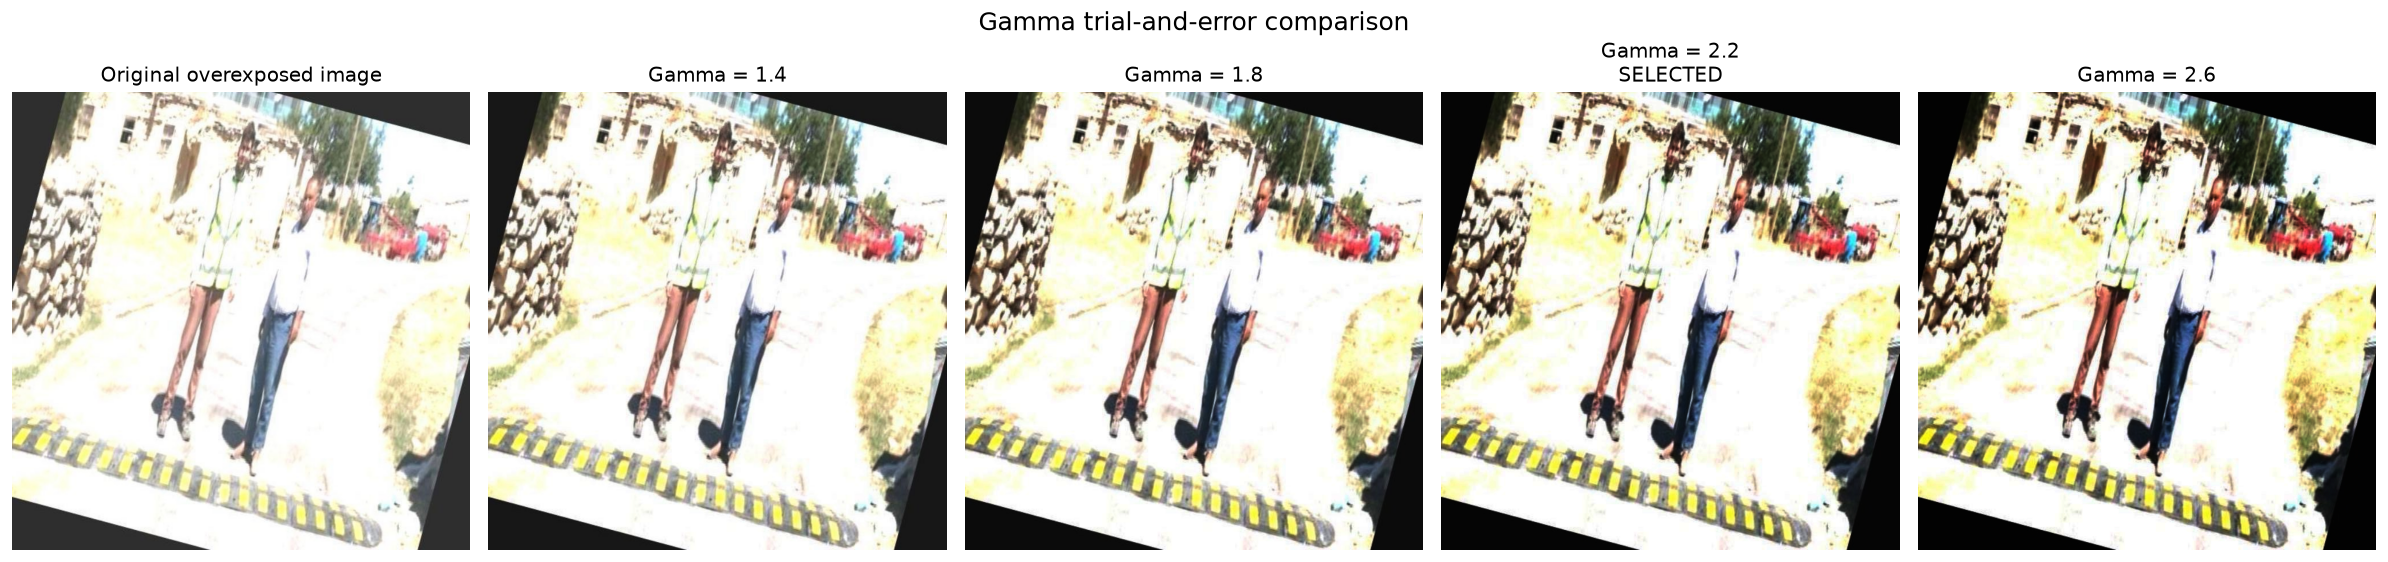

In [5]:
gamma_path = PP_DIR / "gamma.jpg"
gamma_source = read_bgr(gamma_path)
gamma_trials = {}
gamma_trial_metrics = []
selected_gamma = PARAMS["selected_gamma"]

fig, axes = plt.subplots(1, len(PARAMS["gamma_trials"]) + 1, figsize=(20, 5))
axes[0].imshow(to_rgb(gamma_source))
axes[0].set_title("Original overexposed image")
axes[0].axis("off")

for axis, gamma_value in zip(axes[1:], PARAMS["gamma_trials"]):
    trial_result = gamma_correction(gamma_source, gamma_value)
    gamma_trials[gamma_value] = trial_result
    metrics = gamma_metrics(trial_result)
    gamma_trial_metrics.append({"gamma": gamma_value, **metrics})
    selected_label = "\nSELECTED" if gamma_value == selected_gamma else ""
    axis.imshow(to_rgb(trial_result))
    axis.set_title(f"Gamma = {gamma_value}{selected_label}")
    axis.axis("off")

plt.suptitle("Gamma trial-and-error comparison", fontsize=15)
plt.tight_layout()
plt.show()

print(f"{'Gamma':>8} {'Mean brightness':>18} {'Clipped highlights (%)':>24}")
for row in gamma_trial_metrics:
    print(
        f"{row['gamma']:>8.1f} "
        f"{row['mean_brightness']:>18.2f} "
        f"{row['clipped_highlights_pct']:>24.2f}"
    )

gamma_corrected = gamma_trials[selected_gamma]
gamma_output_path = save_bgr(OUTPUT_DIR / "PP" / "gamma_corrected.jpg", gamma_corrected)
print(f"Selected gamma: {selected_gamma}")
print(f"Saved selected result only: {gamma_output_path}")

## 5. Spatial filtering — sharpen and denoise

The sharpening result is saved directly. For denoising, several median-kernel sizes are displayed for trial-and-error comparison while the bilateral-filter settings remain fixed. Only the visually selected result is saved under `outputs/SF` and copied into `HP` for the next stage.

Selected median kernel: 9 x 9
Saved selected SF output: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\SF\sharpen_sharpened.jpg
Copied selected result for histogram processing: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\HP\sharpen_sharpened.jpg
Saved selected SF output: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\SF\SpatialFilteringDenoising1_denoised.jpg
Copied selected result for histogram processing: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\HP\SpatialFilteringDenoising1_denoised.jpg
Saved selected SF output: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\SF\SpatialFilteringDenoising2_denoised.jpg
Copied selected result for histogram processing: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\HP\SpatialFilteringDenoising2_denoised.jpg


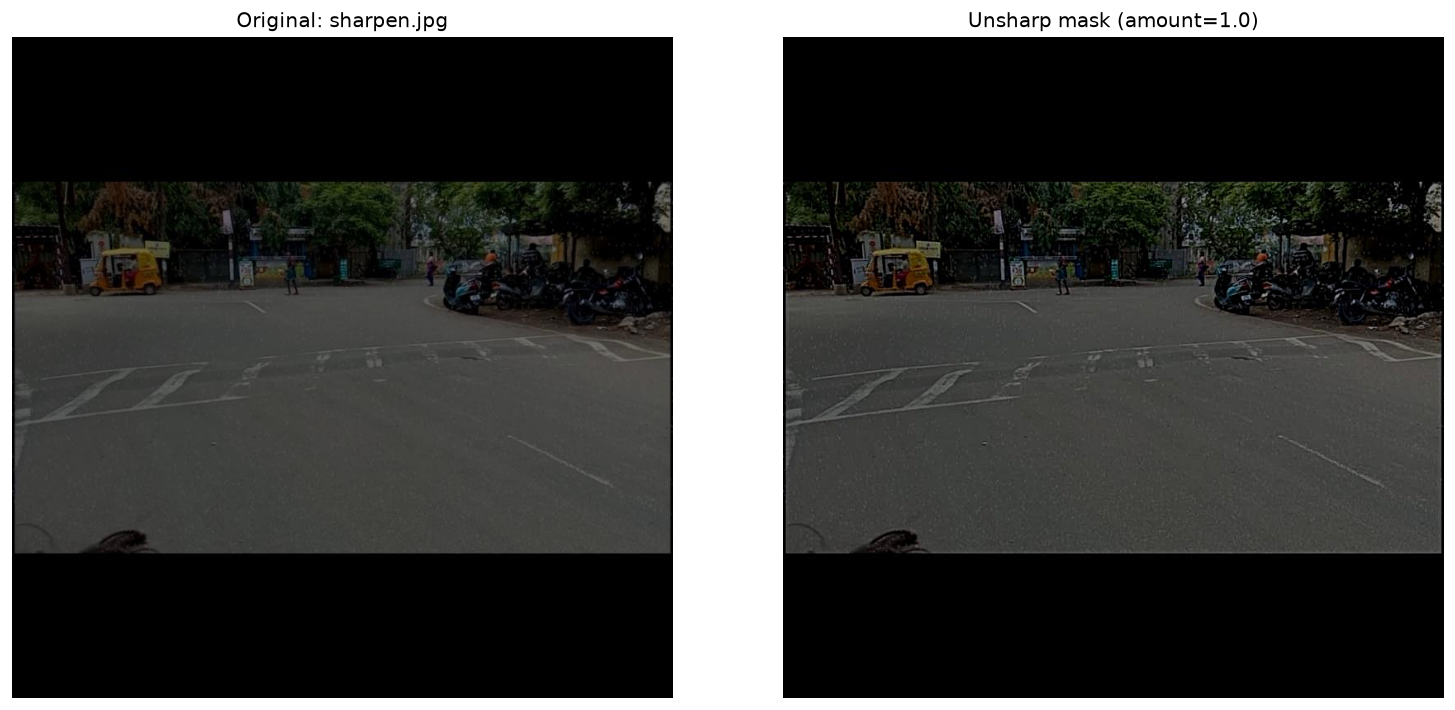

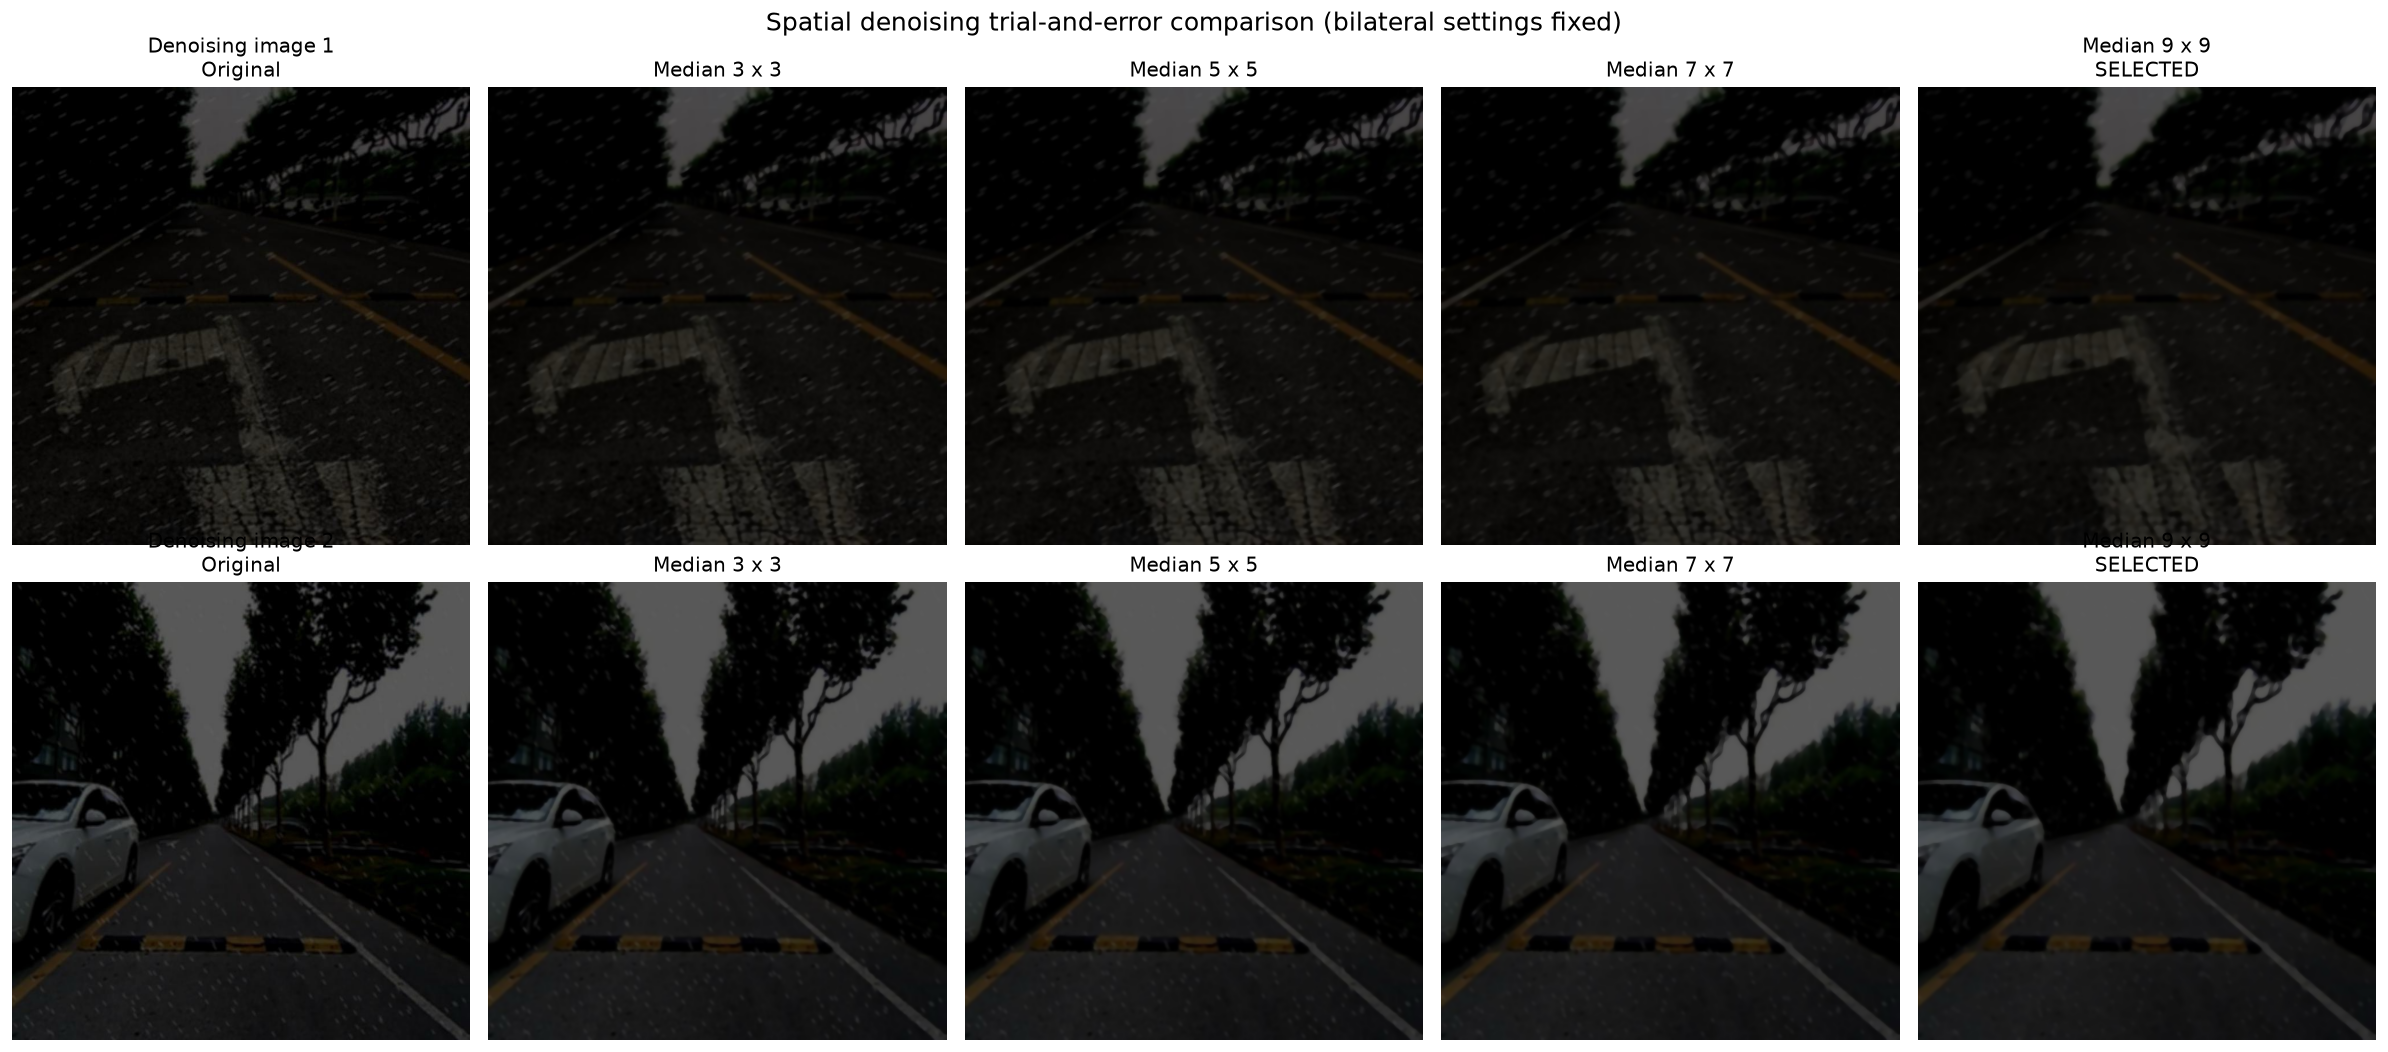

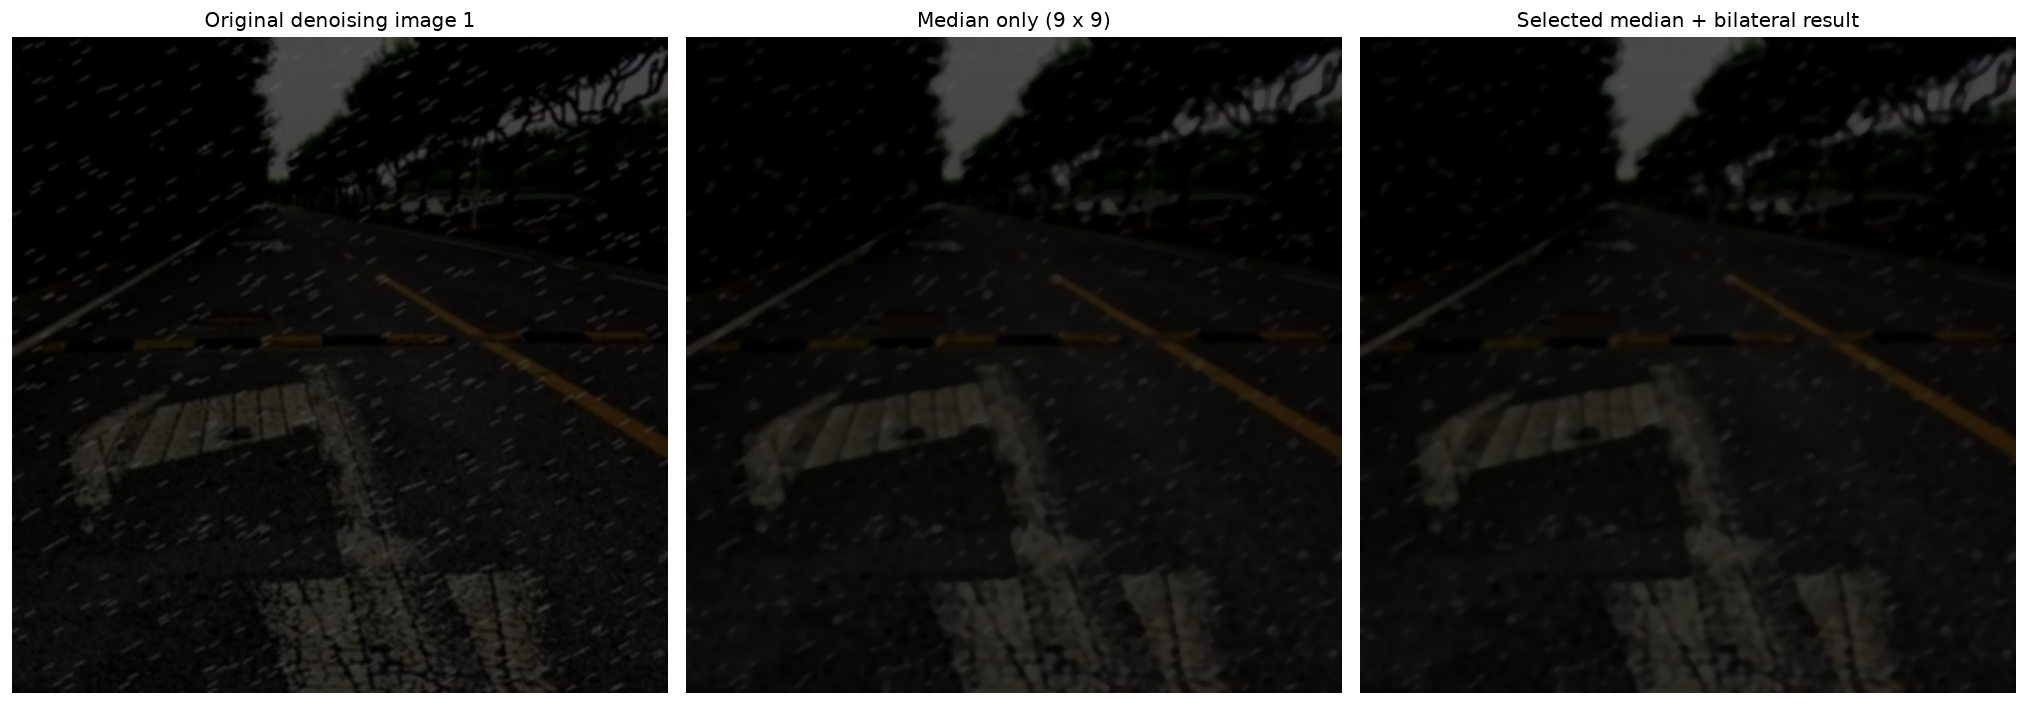

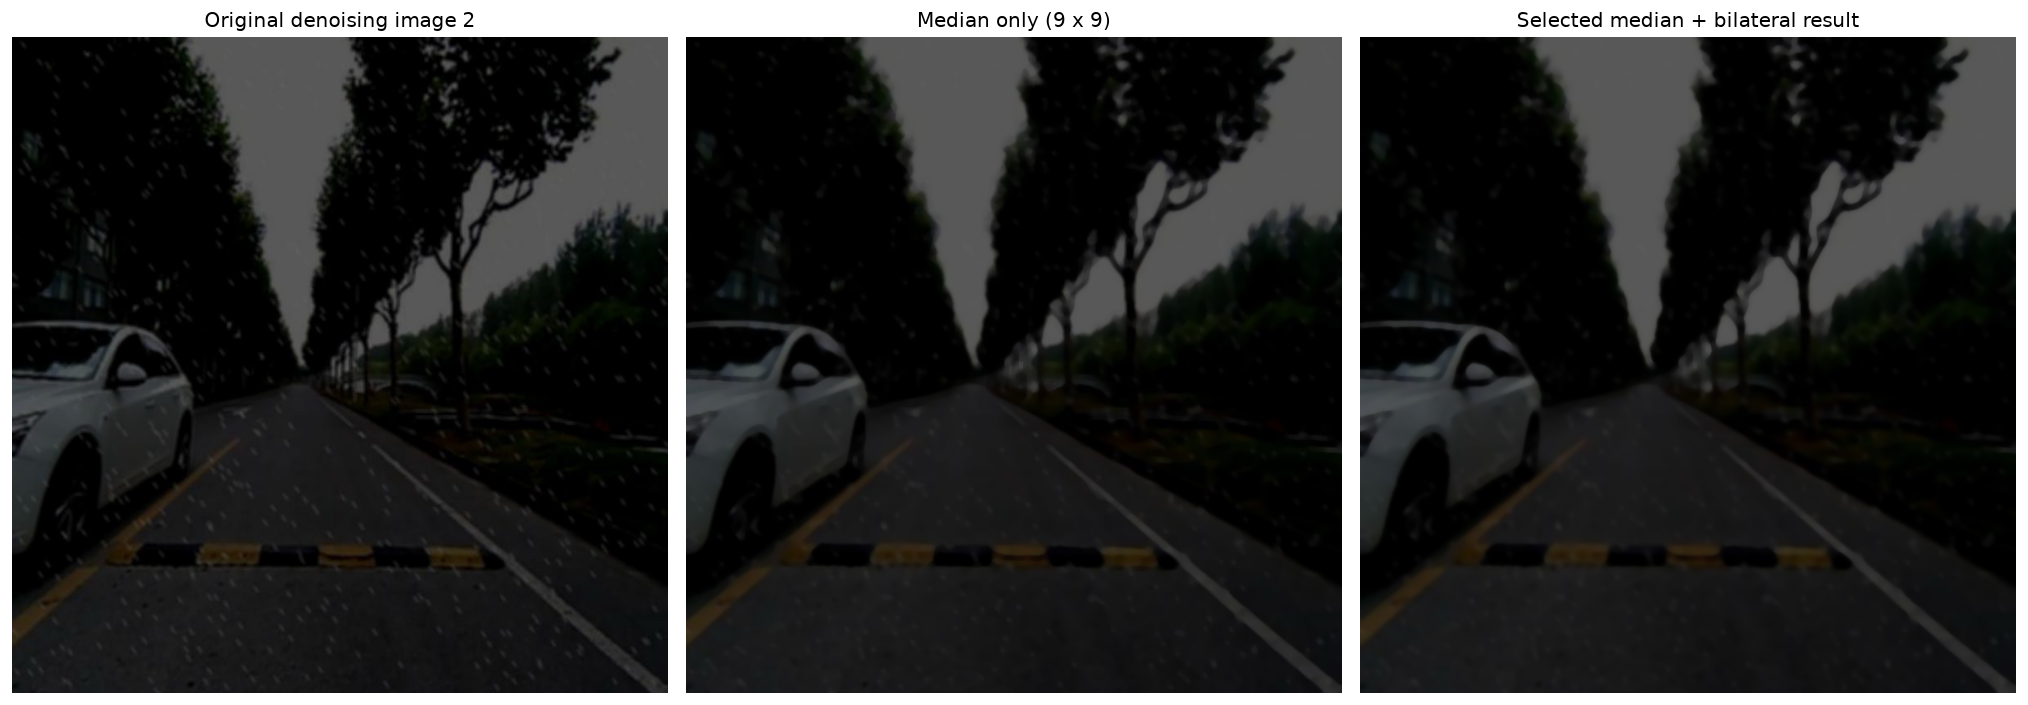

In [6]:
sf_results = {}

# Filename-driven sharpening.
sharpen_path = SF_DIR / "sharpen.jpg"
sharpen_source = read_bgr(sharpen_path)
sharpen_base = cv2.GaussianBlur(sharpen_source, (0, 0), sigmaX=2.0)
amount = PARAMS["unsharp_amount"]
sharpened = cv2.addWeighted(sharpen_source, 1.0 + amount, sharpen_base, -amount, 0)
sf_results["sharpen_sharpened.jpg"] = sharpened
show_images(
    [to_rgb(sharpen_source), to_rgb(sharpened)],
    ["Original: sharpen.jpg", f"Unsharp mask (amount={amount})"],
    figsize=(13, 6),
)

# Trial-and-error comparison for spatial denoising.
denoising_sources = {
    index: read_bgr(SF_DIR / f"SpatialFilteringDenoising{index}.jpg")
    for index in (1, 2)
}
denoising_trials = {index: {} for index in denoising_sources}
selected_kernel = PARAMS["selected_median_kernel"]
trial_kernels = PARAMS["median_kernel_trials"]
fig, axes = plt.subplots(len(denoising_sources), len(trial_kernels) + 1, figsize=(20, 9))

for row, (index, source) in enumerate(denoising_sources.items()):
    axes[row, 0].imshow(to_rgb(source))
    axes[row, 0].set_title(f"Denoising image {index}\nOriginal")
    axes[row, 0].axis("off")
    for col, kernel_size in enumerate(trial_kernels, start=1):
        median_result, trial_result = spatial_denoise(source, kernel_size)
        denoising_trials[index][kernel_size] = (median_result, trial_result)
        selected_label = "\nSELECTED" if kernel_size == selected_kernel else ""
        axes[row, col].imshow(to_rgb(trial_result))
        axes[row, col].set_title(f"Median {kernel_size} x {kernel_size}{selected_label}")
        axes[row, col].axis("off")

plt.suptitle("Spatial denoising trial-and-error comparison (bilateral settings fixed)", fontsize=15)
plt.tight_layout()
plt.show()

# Show the intermediate median result for the selected setting, then keep only the final selected output.
for index, source in denoising_sources.items():
    selected_median, selected_denoised = denoising_trials[index][selected_kernel]
    output_name = f"SpatialFilteringDenoising{index}_denoised.jpg"
    sf_results[output_name] = selected_denoised
    show_images(
        [to_rgb(source), to_rgb(selected_median), to_rgb(selected_denoised)],
        [
            f"Original denoising image {index}",
            f"Median only ({selected_kernel} x {selected_kernel})",
            "Selected median + bilateral result",
        ],
        figsize=(17, 6),
    )

print(f"Selected median kernel: {selected_kernel} x {selected_kernel}")
hp_generated_paths = []
for output_name, result in sf_results.items():
    sf_output_path = save_bgr(OUTPUT_DIR / "SF" / output_name, result)
    hp_path = save_bgr(HP_DIR / output_name, result)
    hp_generated_paths.append(hp_path)
    print(f"Saved selected SF output: {sf_output_path}")
    print(f"Copied selected result for histogram processing: {hp_path}")

## 6. Histogram processing — every image in `HP`

CLAHE is applied only to the LAB luminance channel. This improves local contrast without independently distorting the red, green, and blue channels. The processed images are saved to `outputs/HP`; the source images remain in `HP`.

Saved histogram-processed output: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\HP\sharpen_sharpened_histogram_processed.jpg
Saved histogram-processed output: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\HP\SpatialFilteringDenoising1_denoised_histogram_processed.jpg
Saved histogram-processed output: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs\HP\SpatialFilteringDenoising2_denoised_histogram_processed.jpg


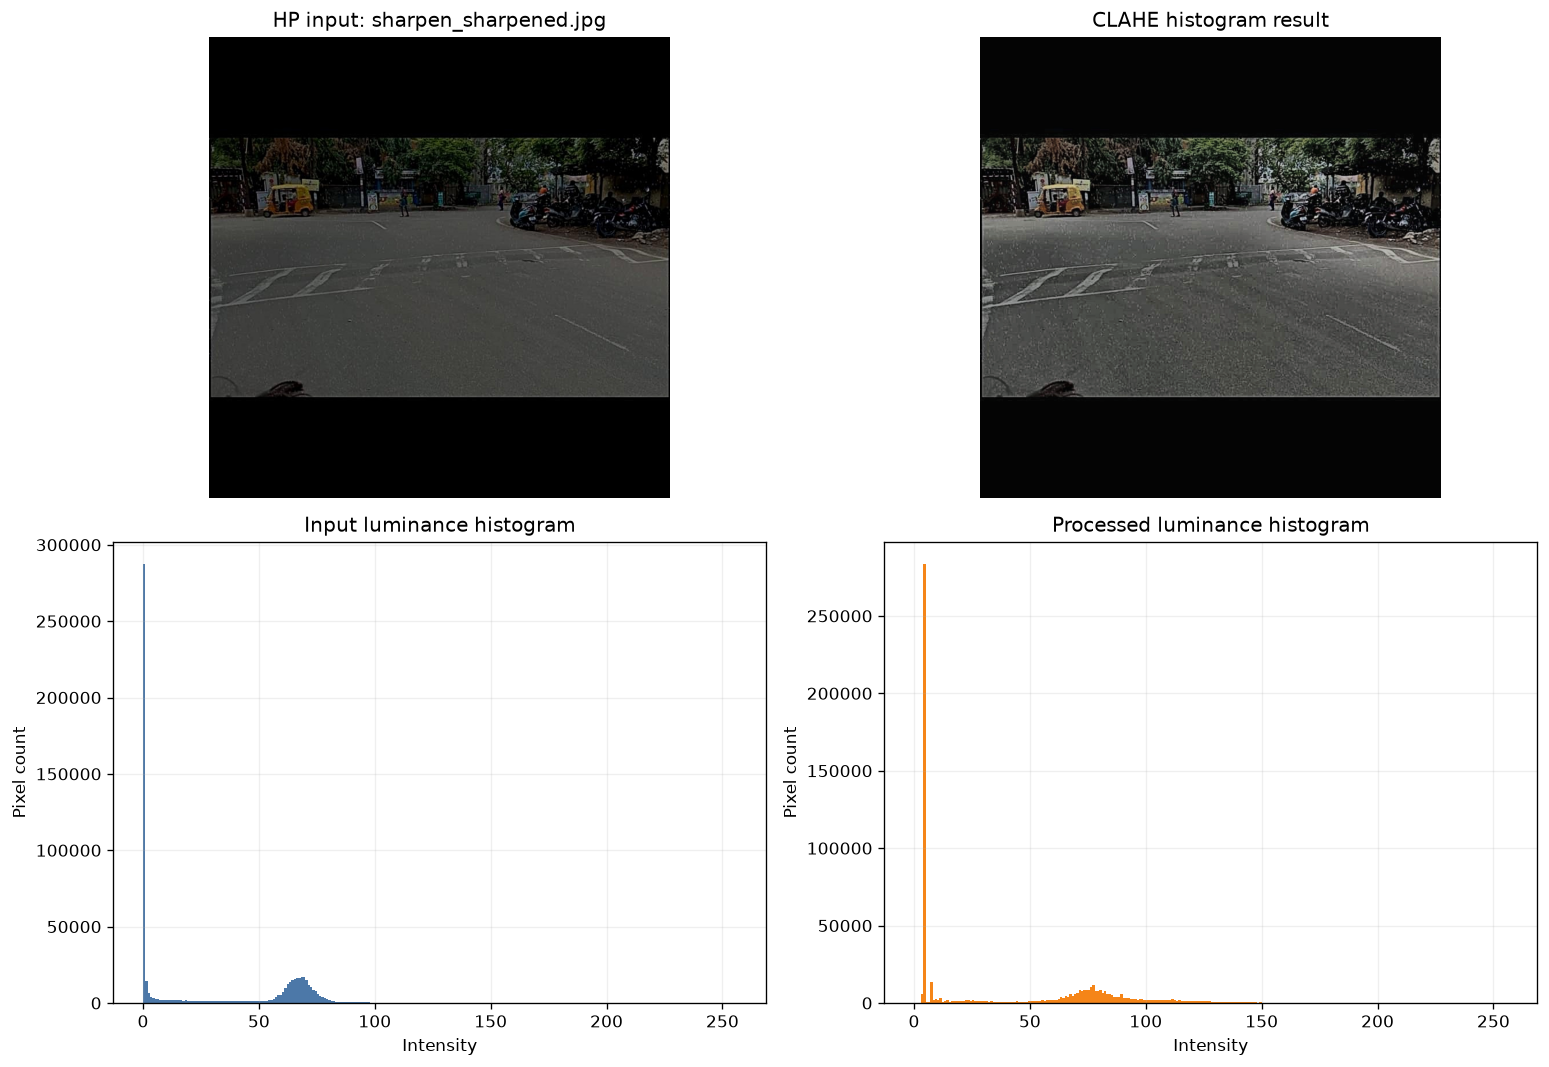

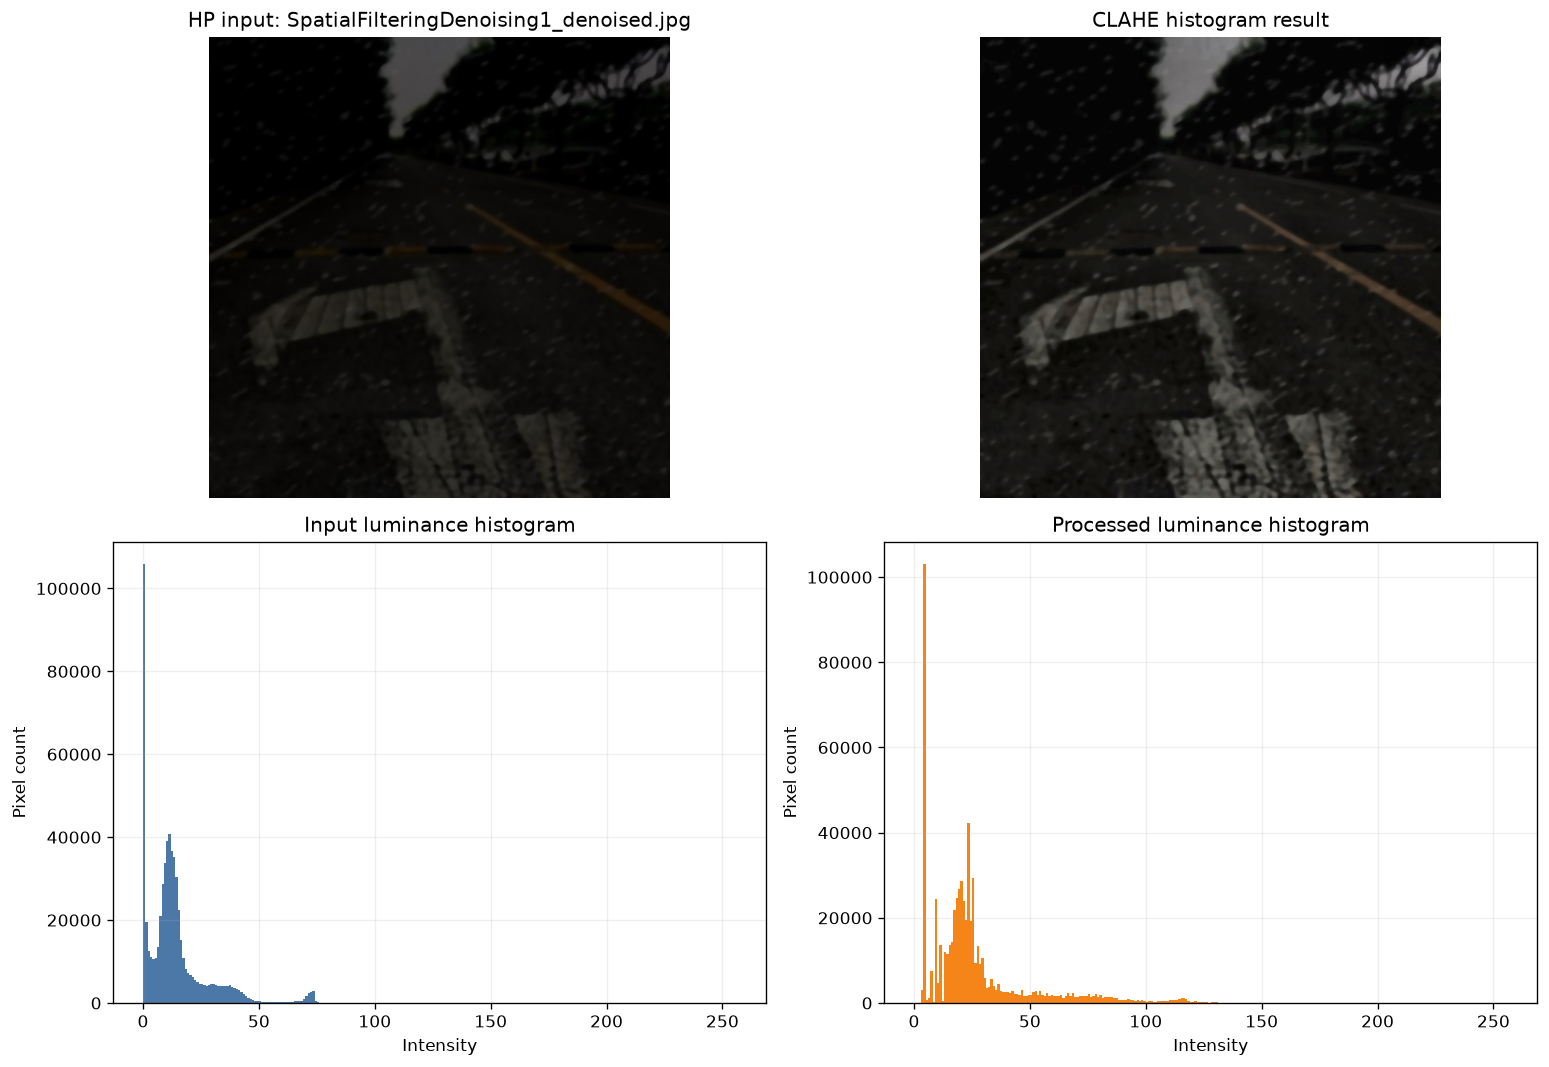

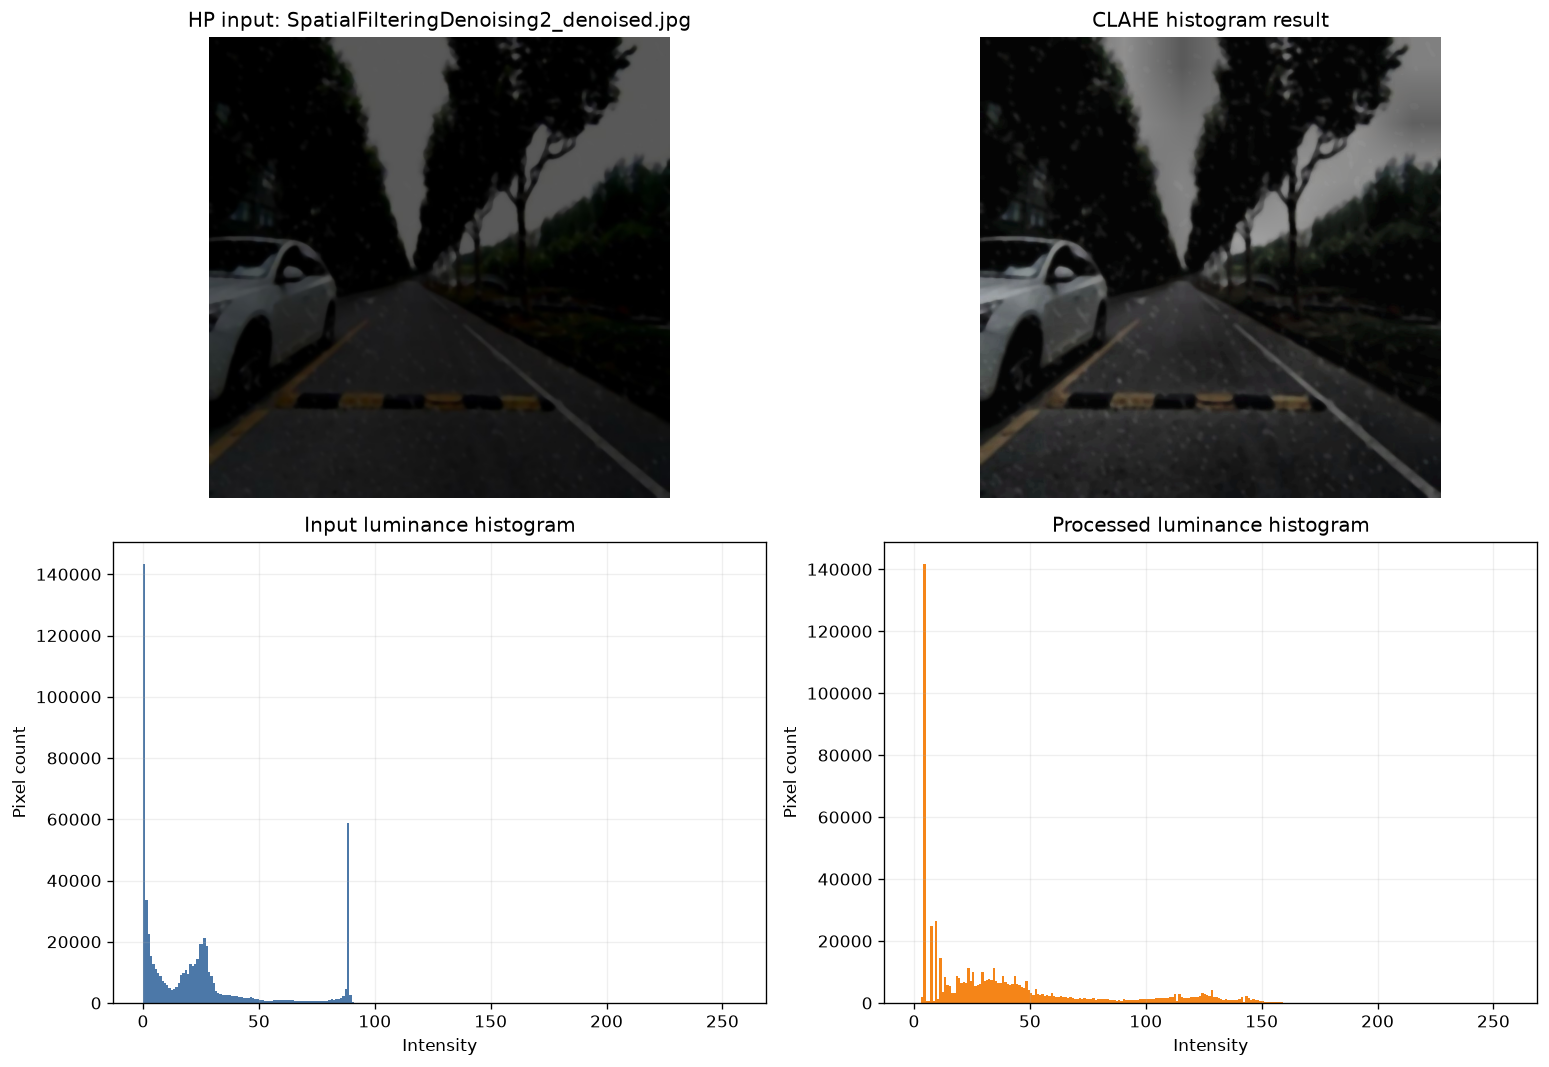

In [7]:
def clahe_luminance(image_bgr: np.ndarray) -> np.ndarray:
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    clahe = cv2.createCLAHE(
        clipLimit=PARAMS["clahe_clip_limit"],
        tileGridSize=PARAMS["clahe_grid"],
    )
    enhanced_lightness = clahe.apply(lightness)
    enhanced_lab = cv2.merge((enhanced_lightness, channel_a, channel_b))
    return cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)

hp_source_paths = sorted(
    path for path in HP_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
)
if not hp_source_paths:
    raise RuntimeError(f"No images are available for histogram processing in {HP_DIR}")

hp_output_paths = []
for source_path in hp_source_paths:
    source = read_bgr(source_path)
    enhanced = clahe_luminance(source)
    output_path = save_bgr(
        OUTPUT_DIR / "HP" / f"{source_path.stem}_histogram_processed.jpg",
        enhanced,
    )
    hp_output_paths.append(output_path)

    source_gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
    enhanced_gray = cv2.cvtColor(enhanced, cv2.COLOR_BGR2GRAY)
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    axes[0, 0].imshow(to_rgb(source))
    axes[0, 0].set_title(f"HP input: {source_path.name}")
    axes[0, 1].imshow(to_rgb(enhanced))
    axes[0, 1].set_title("CLAHE histogram result")
    for axis in axes[0]:
        axis.axis("off")
    axes[1, 0].hist(source_gray.ravel(), bins=256, range=(0, 256), color="#4C78A8")
    axes[1, 0].set_title("Input luminance histogram")
    axes[1, 1].hist(enhanced_gray.ravel(), bins=256, range=(0, 256), color="#F58518")
    axes[1, 1].set_title("Processed luminance histogram")
    for axis in axes[1]:
        axis.set_xlabel("Intensity")
        axis.set_ylabel("Pixel count")
        axis.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    print(f"Saved histogram-processed output: {output_path}")

## 7. Reproducibility checks and output summary

In [8]:
required_inputs = [
    ED_DIR / "Edge.jpg",
    PP_DIR / "gamma.jpg",
    SF_DIR / "sharpen.jpg",
    SF_DIR / "SpatialFilteringDenoising1.jpg",
    SF_DIR / "SpatialFilteringDenoising2.jpg",
]
assert all(path.exists() for path in required_inputs), "One or more required source images are missing."
assert len(hp_generated_paths) == 3 and all(path.exists() for path in hp_generated_paths)
assert len(hp_output_paths) >= 3 and all(path.exists() for path in hp_output_paths)

assert selected_gamma in gamma_trials
assert selected_kernel in PARAMS["median_kernel_trials"]
print("Processing completed successfully.")
print(f"Selected gamma: {selected_gamma}")
print(f"Selected median kernel: {selected_kernel} x {selected_kernel}")
print()
print("Three SF-derived files placed in HP:")
for path in hp_generated_paths:
    print(f"  - {path.name}")
print()
print("Histogram-processed outputs:")
for path in hp_output_paths:
    print(f"  - {path.relative_to(BASE_DIR)}")
print()
print(f"All output groups: {OUTPUT_DIR}")

Processing completed successfully.
Selected gamma: 2.2
Selected median kernel: 9 x 9

Three SF-derived files placed in HP:
  - sharpen_sharpened.jpg
  - SpatialFilteringDenoising1_denoised.jpg
  - SpatialFilteringDenoising2_denoised.jpg

Histogram-processed outputs:
  - outputs\HP\sharpen_sharpened_histogram_processed.jpg
  - outputs\HP\SpatialFilteringDenoising1_denoised_histogram_processed.jpg
  - outputs\HP\SpatialFilteringDenoising2_denoised_histogram_processed.jpg

All output groups: C:\Users\sunlo\OneDrive\Desktop\DIP\Project\Preli\outputs
